# 2D U(2) Base-Eval Inference Bottleneck

This notebook explains why production `2du2/evaluation/base` FT-HMC is slow.
The object is the L16, train/eval $\beta=10$, seed 1107 run in
[`2du2/evaluation/base/logs/fthmc_base_L16_train_b10.0_eval_b10.0_1107.log`](../2du2/evaluation/base/logs/fthmc_base_L16_train_b10.0_eval_b10.0_1107.log),
with the matching HMC log as the cheap baseline.

**What is being profiled.** [`profile_inference.py`](2du2_bottleneck/profile_inference.py)
times the production `HMCU2FT` path, then ahead-of-time (AOT) compiles
isolated pieces of the same graph. AOT here means `jit → lower → compile`,
then `cost_analysis()` and a short replay on the compiled XLA module.

One `fthmc_step` is one compiled Metropolis trajectory. For production
$n_{\mathrm{steps}}=10$ that graph already contains:

- **21 `force` calls** ($2n_{\mathrm{steps}}+1$), from Omelyan
- **2 `new_action` calls**, for $H_{\mathrm{old}}$ and $H_{\mathrm{new}}$

So `fthmc_step` time and FLOPs already include those 21+2 evaluations.
Isolated `force` / `new_action` exist only to attribute cost *inside*
that step; do not add them on top of it. $21\times$ isolated `force` is
a check that the compiled step is essentially 21 transformed forces.

The other kernels are nested pieces of those two, plus the Wilson HMC
counterparts:

- `cnn_apply`: one of the 8 subset CNNs (inside `forward` / `jac_logdet`).
- `forward`: full field transformation (inside `new_action`).
- `jac_logdet`: Jacobian log-det of that transformation (inside `new_action`).
- `new_action`: $S_{\mathrm{Wilson}}(\mathrm{FT}(U))-\log\det J$. One scalar evaluation.
- `force`: $\nabla$ `new_action` (one left-algebra perturbation). One gradient evaluation.
- `hmc_force` / `hmc_step`: Wilson HMC counterparts (no field transformation). 
- `hmc_step` likewise contains 21 `hmc_force` + 2 Wilson actions.

Wall-clock `metropolis_step` is the same compiled step on the production
Python path. Per-config eval extras (another `forward` + plaquette + topology)
sit outside `fthmc_step`.

Dumps live in [`2du2_bottleneck/dumps/`](2du2_bottleneck/dumps/), plots in
[`2du2_bottleneck/plots/`](2du2_bottleneck/plots/). Profile jobs use the
same PBS/XLA env as `2du2/evaluation/base/gen_sub.sh` and the same
`HMCU2FT` path as `compare_fthmc.py`. PBS 184789 is production
`jax.checkpoint` on; PBS 184790 is the same graph with
`scan_checkpoint=False`.

In [8]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

cwd = Path.cwd()
REPO_ROOT = cwd if (cwd / "2du2").exists() else cwd.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

from nthmc.core.plot_settings import color_ls, default_plot, fs_p, fs_small_p

LATTICE_SIZE = 16
BETA = 10.0
TRAIN_BETA = 10.0
N_STEPS = 10
N_CONFIGS = 2048
N_THERM = 200
SEED = 1107
MODEL_TAG = "base"
SAVE_TAG = f"{MODEL_TAG}_train_b{BETA:.1f}_L{LATTICE_SIZE}_{SEED}"
FORCE_CALLS = 2 * N_STEPS + 1

FT_LOG = REPO_ROOT / "2du2" / "evaluation" / "base" / "logs" / f"fthmc_{MODEL_TAG}_L{LATTICE_SIZE}_train_b{TRAIN_BETA:.1f}_eval_b{BETA:.1f}_{SEED}.log"
HMC_LOG = REPO_ROOT / "2du2" / "evaluation" / "hmc" / "logs" / f"hmc_L{LATTICE_SIZE}_b{BETA:.1f}_{SEED}.log"
DUMP = (
    REPO_ROOT / "presentation" / "2du2_bottleneck" / "dumps"
    / f"inference_profile_L{LATTICE_SIZE}_beta{BETA:.1f}_nsteps{N_STEPS}_{SAVE_TAG}.json"
)
DUMP_NOREM = (
    REPO_ROOT / "presentation" / "2du2_bottleneck" / "dumps"
    / f"inference_profile_L{LATTICE_SIZE}_beta{BETA:.1f}_nsteps{N_STEPS}_{SAVE_TAG}_norem.json"
)
NOREM_LOG = (
    REPO_ROOT / "presentation" / "2du2_bottleneck" / "logs"
    / f"profile_{MODEL_TAG}_L{LATTICE_SIZE}_train_b{TRAIN_BETA:.1f}_eval_b{BETA:.1f}_{SEED}_norem.log"
)
PLOT_DIR = REPO_ROOT / "presentation" / "2du2_bottleneck" / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [9]:
def last_float(pattern, text):
    matches = list(re.finditer(pattern, text, re.MULTILINE))
    return float(matches[-1].group(1)) if matches else None


def tqdm_rates(text, desc):
    rows = re.findall(
        rf"{re.escape(desc)}:\s+\d+%\|.*?\|\s+(\d+)/(\d+)\s+\[(?P<elapsed>[^,]+)<(?P<remain>[^,]+),\s+(?P<rate>[\d.]+)s/it\]",
        text,
    )
    if not rows:
        return None, None, None
    rates = [float(row[4]) for row in rows]
    return rates[0], rates[-1], int(rows[0][1]) * rates[0] / 3600.0


def load_log(path):
    text = path.read_text(errors="replace").replace("\r", "\n")
    therm_first, therm_last, therm_proj_h = tqdm_rates(text, "Thermalizing FT-HMC")
    run_first, run_last, _ = tqdm_rates(text, "Running FT-HMC")
    return {
        "path": path,
        "model_load_s": last_float(r">>> Model loaded in ([0-9.]+) seconds", text),
        "therm_s": last_float(r">>> FT thermalization completed in ([0-9.]+) seconds", text)
        or last_float(r">>> HMC thermalization completed in ([0-9.]+) seconds", text),
        "run_s": last_float(r">>> FT-HMC run completed in ([0-9.]+) seconds", text)
        or last_float(r">>> HMC run completed in ([0-9.]+) seconds", text),
        "total_s": last_float(r">>> Total FT-HMC time: ([0-9.]+) seconds", text)
        or last_float(r">>> Total HMC time: ([0-9.]+) seconds", text),
        "first_compile_s": therm_first,
        "therm_steady_s": therm_last,
        "therm_projected_h": therm_proj_h,
        "run_first_s": run_first,
        "run_steady_s": run_last,
        "cuda_graph_oom": "instantiate CUDA graph" in text,
    }


ft_log = load_log(FT_LOG)
hmc_log = load_log(HMC_LOG)
profile = json.loads(DUMP.read_text()) if DUMP.exists() else None
profile_norem = json.loads(DUMP_NOREM.read_text()) if DUMP_NOREM.exists() else None

ft_total_h = ft_log["total_s"] / 3600 if ft_log["total_s"] else None
hmc_total_h = hmc_log["total_s"] / 3600 if hmc_log["total_s"] else None
speedup = (ft_log["total_s"] / hmc_log["total_s"]) if ft_log["total_s"] and hmc_log["total_s"] else None
run_hours = N_CONFIGS * (ft_log["run_steady_s"] or 0) / 3600

lines = [
    "## Production log (seed 1107, L=16, $\\beta=10$, fixed $dt=0.10$)",
    "",
    f"- FT-HMC Python total: **{ft_log['total_s']:.0f} s ({ft_total_h:.2f} h)**",
    f"- First therm step / compile: **{ft_log['first_compile_s']:.1f} s**; tqdm projected **{ft_log['therm_projected_h']:.1f} h**",
    f"- Steady therm / run: **{ft_log['therm_steady_s']:.2f} s/it** / **{ft_log['run_steady_s']:.2f} s/it**",
    f"- 2048 configs at the run rate: **{run_hours:.2f} h**",
    f"- HMC Python total: **{hmc_log['total_s']:.1f} s ({hmc_total_h:.3f} h)**; FT/HMC = **{speedup:.0f}×**",
    f"- CUDA-graph OOM in this log: **{ft_log['cuda_graph_oom']}**",
]
if profile is None:
    lines.append("- Remat profile dump is not ready yet (PBS 184789).")
else:
    ft_wall = profile["wall_clock"]["fthmc"]
    hmc_wall = profile["wall_clock"]["hmc"]
    lines.append(
        f"- Remat profile: first FT step **{ft_wall['first_step_s']:.1f} s**, "
        f"steady **{ft_wall['steady_mean_s']:.3f} s**, HMC steady **{hmc_wall['steady_mean_s']:.4f} s**"
    )
if profile_norem is None:
    if NOREM_LOG.exists() and "Can't pack device memory arguments" in NOREM_LOG.read_text(errors="replace"):
        norem_text = NOREM_LOG.read_text(errors="replace")
        packed = re.search(
            r"Can't pack device memory arguments array of size (\d+) which is larger than the maximum supported size of (\d+)",
            norem_text,
        )
        if packed:
            lines.append(
                f"- No-remat PBS 184790 **failed at first `metropolis_step` compile**: "
                f"XLA packed **{packed.group(1)}** device-memory args, limit **{packed.group(2)}**. "
                f"No `{DUMP_NOREM.name}` was written."
            )
        else:
            lines.append("- No-remat PBS 184790 failed to compile; no dump was written.")
    else:
        lines.append("- No-remat profile dump is not ready yet (PBS 184790).")
else:
    ft_norem = profile_norem["wall_clock"]["fthmc"]
    lines.append(
        f"- No-remat profile: first FT step **{ft_norem['first_step_s']:.1f} s**, "
        f"steady **{ft_norem['steady_mean_s']:.3f} s**"
    )
display(Markdown("\n".join(lines)))

## Production log (seed 1107, L=16, $\beta=10$, fixed $dt=0.10$)

- FT-HMC Python total: **14061 s (3.91 h)**
- First therm step / compile: **494.5 s**; tqdm projected **27.5 h**
- Steady therm / run: **8.60 s/it** / **6.03 s/it**
- 2048 configs at the run rate: **3.43 h**
- HMC Python total: **145.5 s (0.040 h)**; FT/HMC = **97×**
- CUDA-graph OOM in this log: **False**
- Remat profile: first FT step **488.4 s**, steady **1.420 s**, HMC steady **0.0051 s**
- No-remat PBS 184790 **failed at first `metropolis_step` compile**: XLA packed **1906** device-memory args, limit **1024**. No `inference_profile_L16_beta10.0_nsteps10_base_train_b10.0_L16_1107_norem.json` was written.

## Why tqdm said tens of hours

The production sampler is a Python loop over `HMCU2FT.metropolis_step`. The first call JIT-compiles the full Omelyan trajectory (`n_steps=10`). That compile is ~8 min. tqdm uses the first-step rate, so 200 therm steps look like ~27 h. After the compiled executable exists, each config is ~6.0 s on seed 1107.

If step-size tuning were on (`n_tune_steps=1000`, up to 10 attempts), the same 6 s/step would add up to ~17 h of tuning on top of the 3.9 h production chain. That is the 18 h figure. This log and current `gen_sub.sh` are fixed-step.

`XLA_PYTHON_CLIENT_PREALLOCATE=false` and empty command buffers match the current eval generator. They avoid the CUDA-graph OOM in this log. They are not the reason FT-HMC is ~100× slower than HMC: HMC does not set those flags and still finishes in minutes because the Wilson force graph is tiny.

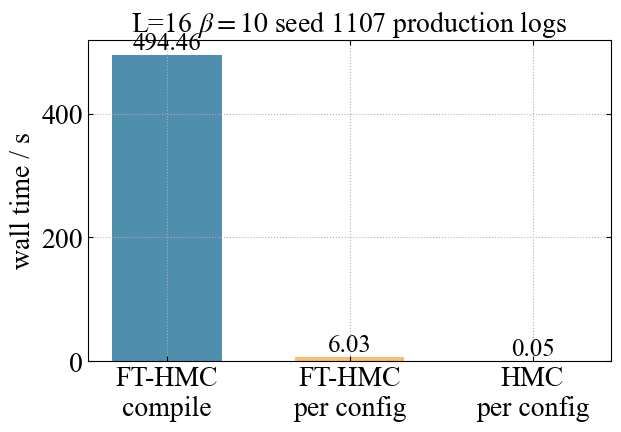

In [10]:
fig, ax = default_plot()
labels = ["FT-HMC\ncompile", "FT-HMC\nper config", "HMC\nper config"]
values = [
    ft_log["first_compile_s"] or np.nan,
    ft_log["run_steady_s"] or np.nan,
    (hmc_log["run_s"] / N_CONFIGS) if hmc_log["run_s"] else np.nan,
]
bars = ax.bar(labels, values, color=[color_ls[0], color_ls[1], color_ls[2]], width=0.6)
ax.set_ylabel(r"wall time / s", **fs_p)
ax.set_title(r"L=16 $\beta=10$ seed 1107 production logs", **fs_p)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.2f}", ha="center", va="bottom", **fs_small_p)
fig.savefig(PLOT_DIR / "eval_log_step_times.pdf", transparent=True, bbox_inches="tight")
plt.show()

In [11]:
KERNEL_ORDER = ["cnn_apply", "forward", "jac_logdet", "new_action", "force", "fthmc_step", "hmc_force", "hmc_step"]
KERNEL_LABELS = {
    "cnn_apply": "CNN (1 subset)",
    "forward": "forward (8 subsets)",
    "jac_logdet": r"$\log|J|$",
    "new_action": "new action",
    "force": r"$\nabla$ new action",
    "fthmc_step": "FT-HMC step",
    "hmc_force": "Wilson force",
    "hmc_step": "HMC step",
}


def md_table_cell(text):
    return text.replace("|", r"\|")


def kernel_rows(dump):
    rows = []
    for name in KERNEL_ORDER:
        item = dump["kernels"].get(name)
        if not item:
            continue
        rows.append(
            {
                "name": name,
                "label": KERNEL_LABELS[name],
                "compile_s": item.get("compile_s"),
                "mean_s": item.get("mean_s"),
                "flops": (item.get("cost") or {}).get("flops"),
                "bytes": (item.get("cost") or {}).get("bytes_accessed"),
            }
        )
    return rows


def style_kernel_ticks(ax, labels):
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.tick_params(axis="x", labelsize=11)


if profile is None:
    display(Markdown(f"Profile dump missing: `{DUMP}`. Re-run this notebook after PBS 184789."))
else:
    rows = kernel_rows(profile)
    ft_wall = profile["wall_clock"]["fthmc"]
    force = profile["kernels"]["force"]
    fthmc_step = profile["kernels"]["fthmc_step"]
    extra = ft_wall["run_observable_s"]["mean_s"]
    force_x_calls = FORCE_CALLS * (force["mean_s"] or 0)
    lines = [
        "## Profile replay vs the log",
        "",
        f"- Production compiled step, first call: **{ft_wall['first_step_s']:.1f} s** (log {ft_log['first_compile_s']:.1f} s)",
        f"- Steady `metropolis_step`: **{ft_wall['steady_mean_s']:.3f} s** (log run {ft_log['run_steady_s']:.2f} s/it)",
        f"- Extra Python `forward` + plaquette + $Q$: **{extra:.3f} s**/config",
        f"- Isolated `force` × {FORCE_CALLS} Omelyan calls: **{force_x_calls:.3f} s** vs compiled step **{fthmc_step['mean_s']:.3f} s**",
        f"- Projected 2048-config total: **{profile['extrapolation']['projected_total_s'] / 3600:.2f} h** vs log **{ft_total_h:.2f} h**",
        "",
        "| kernel | compile / s | mean / s | FLOPs | bytes |",
        "|---|---:|---:|---:|---:|",
    ]
    for row in rows:
        flops = f"{row['flops']:.3e}" if row["flops"] is not None else "—"
        nbytes = f"{row['bytes']:.3e}" if row["bytes"] is not None else "—"
        compile_s = f"{row['compile_s']:.2f}" if row["compile_s"] is not None else "—"
        mean_s = f"{row['mean_s']:.4f}" if row["mean_s"] is not None else "—"
        lines.append(f"| {md_table_cell(row['label'])} | {compile_s} | {mean_s} | {flops} | {nbytes} |")
    display(Markdown("\n".join(lines)))


## Profile replay vs the log

- Production compiled step, first call: **488.4 s** (log 494.5 s)
- Steady `metropolis_step`: **1.420 s** (log run 6.03 s/it)
- Extra Python `forward` + plaquette + $Q$: **4.558 s**/config
- Isolated `force` × 21 Omelyan calls: **1.411 s** vs compiled step **1.483 s**
- Projected 2048-config total: **3.88 h** vs log **3.91 h**

| kernel | compile / s | mean / s | FLOPs | bytes |
|---|---:|---:|---:|---:|
| CNN (1 subset) | 0.11 | 0.0001 | 3.686e+04 | 2.122e+05 |
| forward (8 subsets) | 4.59 | 0.0042 | 1.075e+06 | 2.513e+06 |
| $\log\|J\|$ | 12.65 | 0.0108 | 5.335e+06 | 1.328e+07 |
| new action | 17.33 | 0.0143 | 6.458e+06 | 1.589e+07 |
| $\nabla$ new action | 115.67 | 0.0672 | 3.761e+07 | 8.339e+07 |
| FT-HMC step | 0.00 | 1.4827 | 1.648e+08 | 3.693e+08 |
| Wilson force | 1.12 | 0.0002 | 3.238e+05 | 7.557e+05 |
| HMC step | 0.00 | 0.0049 | 1.829e+06 | 4.090e+06 |

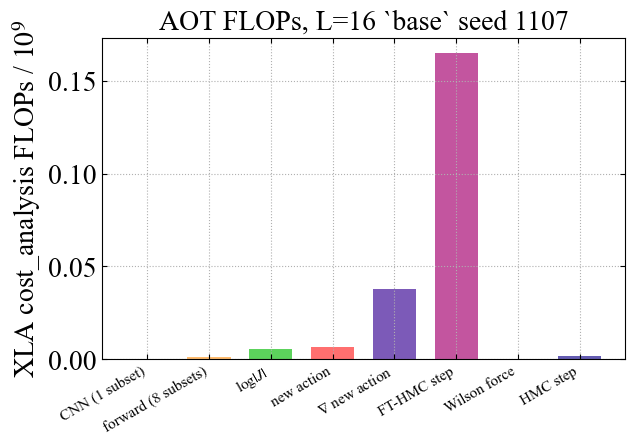

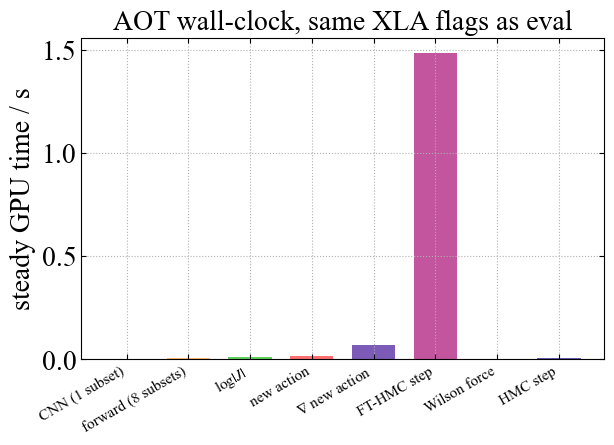

In [12]:
if profile is not None:
    rows = [row for row in kernel_rows(profile) if row["flops"] is not None]
    labels = [row["label"] for row in rows]
    fig, ax = default_plot()
    ax.bar(np.arange(len(rows)), [row["flops"] / 1e9 for row in rows], color=color_ls[: len(rows)], width=0.7)
    ax.set_ylabel(r"XLA cost_analysis FLOPs / $10^9$", **fs_p)
    ax.set_title(r"AOT FLOPs, L=16 `base` seed 1107", **fs_p)
    style_kernel_ticks(ax, labels)
    fig.savefig(PLOT_DIR / "kernel_flops.pdf", transparent=True, bbox_inches="tight")
    plt.show()

    rows_t = [row for row in kernel_rows(profile) if row["mean_s"] is not None]
    labels_t = [row["label"] for row in rows_t]
    fig, ax = default_plot()
    ax.bar(np.arange(len(rows_t)), [row["mean_s"] for row in rows_t], color=color_ls[: len(rows_t)], width=0.7)
    ax.set_ylabel(r"steady GPU time / s", **fs_p)
    ax.set_title(r"AOT wall-clock, same XLA flags as eval", **fs_p)
    style_kernel_ticks(ax, labels_t)
    fig.savefig(PLOT_DIR / "kernel_times.pdf", transparent=True, bbox_inches="tight")
    plt.show()


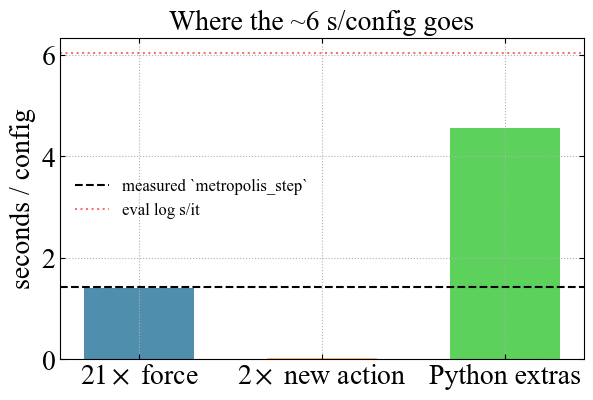

The black dashed line is the compiled sampler only. The dotted log s/it includes the unjitted Python extras, which are larger than the compiled step on this L16 run.

In [13]:
if profile is not None:
    ft_wall = profile["wall_clock"]["fthmc"]
    kernels = profile["kernels"]
    parts = {
        r"$21\times$ force": FORCE_CALLS * (kernels["force"]["mean_s"] or 0),
        r"$2\times$ new action": 2 * (kernels["new_action"]["mean_s"] or 0),
        r"Python extras": ft_wall["run_observable_s"]["mean_s"],
    }
    fig, ax = default_plot()
    ax.bar(list(parts), list(parts.values()), color=color_ls[:3], width=0.6)
    ax.axhline(ft_wall["steady_mean_s"], color="black", linestyle="--", label=r"measured `metropolis_step`")
    ax.axhline(ft_log["run_steady_s"], color=color_ls[3], linestyle=":", label=r"eval log s/it")
    ax.set_ylabel(r"seconds / config", **fs_p)
    ax.set_title(r"Where the ~6 s/config goes", **fs_p)
    ax.legend(frameon=False, fontsize=12)
    fig.savefig(PLOT_DIR / "per_config_attribution.pdf", transparent=True, bbox_inches="tight")
    plt.show()

    display(
        Markdown(
            "The black dashed line is the compiled sampler only. The dotted log s/it includes "
            "the unjitted Python extras, which are larger than the compiled step on this L16 run."
        )
    )

## `jax.checkpoint` on vs off

Production eval rematerializes each of the 8 subset scans during `jax.grad(new_action)`. PBS 184789 keeps that and wrote a dump. PBS 184790 is the same graph with `scan_checkpoint=False`. It finished, but the first compiled `metropolis_step` died with `Can't pack device memory arguments array of size 1906 which is larger than the maximum supported size of 1024`. There is no `_norem.json` because the job never reached timing or AOT. Remat is required on this L16 graph: without it XLA tries to pass too many live buffers, not merely more FLOPs.

In [14]:
COMPARE_KERNELS = ["forward", "jac_logdet", "new_action", "force", "fthmc_step"]


def fmt(value, pattern=".3f"):
    if value is None:
        return "—"
    return format(value, pattern)


def kernel_flops(item):
    return (item.get("cost") or {}).get("flops")


def kernel_temp_bytes(item):
    memory = item.get("memory") or {}
    if not isinstance(memory, dict):
        return None
    return memory.get("temp_size_in_bytes")


def norem_compile_error(text):
    match = re.search(
        r"Can't pack device memory arguments array of size (\d+) which is larger than the maximum supported size of (\d+)",
        text,
    )
    if match:
        return (
            f"XLA packed **{match.group(1)}** device-memory arguments; "
            f"the GPU backend limit is **{match.group(2)}**."
        )
    if "out of memory" in text.lower() or "CUDA graph" in text:
        return "the log reports an OOM / CUDA-graph failure."
    if "Traceback" in text:
        return f"`{text.strip().splitlines()[-1]}`"
    return None


if profile is not None and profile_norem is None:
    norem_text = NOREM_LOG.read_text(errors="replace") if NOREM_LOG.exists() else ""
    error = norem_compile_error(norem_text)
    if error:
        display(
            Markdown(
                "\n".join(
                    [
                        "### No-remat compile failed (PBS 184790)",
                        "",
                        f"The job ran ~51 min and **did not write** `{DUMP_NOREM.name}`. "
                        "Failure is on the first `HMCU2FT.metropolis_step` compile, before any steady timing:",
                        "",
                        f"- {error}",
                        "- Same XLA flags and model checkpoint as PBS 184789. Only `scan_checkpoint=False` changed.",
                        "- Without remat, the backward keeps live activations through 8 subset scans × Omelyan, so the executable has too many buffers to pack.",
                        "- **Keep production `jax.checkpoint` on.** There is no wall-clock comparison because the no-remat graph cannot compile on this L16 U(2) step.",
                    ]
                )
            )
        )
    else:
        display(Markdown(f"No-remat dump missing: `{DUMP_NOREM.name}`."))
elif profile is None or profile_norem is None:
    missing = []
    if profile is None:
        missing.append(f"`{DUMP.name}` (PBS 184789, remat on)")
    if profile_norem is None:
        missing.append(f"`{DUMP_NOREM.name}` (PBS 184790, remat off)")
    display(Markdown("Comparison waits for: " + "; ".join(missing) + "."))
else:
    remat_step = profile["wall_clock"]["fthmc"]["steady_mean_s"]
    norem_step = profile_norem["wall_clock"]["fthmc"]["steady_mean_s"]
    ratio = (remat_step / norem_step) if remat_step and norem_step else None
    remat_force_flops = kernel_flops(profile["kernels"]["force"])
    norem_force_flops = kernel_flops(profile_norem["kernels"]["force"])
    flop_ratio = (
        remat_force_flops / norem_force_flops
        if remat_force_flops and norem_force_flops
        else None
    )
    lines = [
        "### Wall-clock and FLOPs with remat on vs off",
        "",
        f"- Steady `metropolis_step`: remat **{fmt(remat_step)} s** vs no-remat **{fmt(norem_step)} s**"
        + (f" (remat/no-remat = **{ratio:.2f}×**)" if ratio else ""),
        f"- Isolated `force` FLOPs: remat **{fmt(remat_force_flops, '.3e')}** vs no-remat **{fmt(norem_force_flops, '.3e')}**"
        + (f" (remat/no-remat = **{flop_ratio:.2f}×**)" if flop_ratio else ""),
        f"- Projected 2048-config total: remat **{profile['extrapolation']['projected_total_s'] / 3600:.2f} h** vs no-remat **{profile_norem['extrapolation']['projected_total_s'] / 3600:.2f} h**",
        "",
        "| kernel | remat s | no-remat s | remat FLOPs | no-remat FLOPs | remat temp B | no-remat temp B |",
        "|---|---:|---:|---:|---:|---:|---:|",
    ]
    labels = []
    remat_times = []
    norem_times = []
    remat_flops = []
    norem_flops = []
    for name in COMPARE_KERNELS:
        left = profile["kernels"][name]
        right = profile_norem["kernels"][name]
        labels.append(KERNEL_LABELS[name])
        remat_times.append(left.get("mean_s") or 0.0)
        norem_times.append(right.get("mean_s") or 0.0)
        remat_flops.append(kernel_flops(left) or 0.0)
        norem_flops.append(kernel_flops(right) or 0.0)
        lines.append(
            f"| {labels[-1]} | {fmt(left.get('mean_s'), '.4f')} | {fmt(right.get('mean_s'), '.4f')} | "
            f"{fmt(kernel_flops(left), '.3e')} | {fmt(kernel_flops(right), '.3e')} | "
            f"{fmt(kernel_temp_bytes(left), '.3e')} | {fmt(kernel_temp_bytes(right), '.3e')} |"
        )
    display(Markdown("\n".join(lines)))

    x = np.arange(len(labels))
    width = 0.36
    fig, ax = default_plot()
    ax.bar(x - width / 2, remat_times, width, label=r"`jax.checkpoint` on", color=color_ls[0])
    ax.bar(x + width / 2, norem_times, width, label=r"`jax.checkpoint` off", color=color_ls[1])
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=11)
    ax.set_ylabel(r"steady GPU time / s", **fs_p)
    ax.set_title(r"Remat vs stored activations, L=16 `base`", **fs_p)
    ax.legend(frameon=False, fontsize=12)
    fig.savefig(PLOT_DIR / "remat_vs_norem_times.pdf", transparent=True, bbox_inches="tight")
    plt.show()

    fig, ax = default_plot()
    ax.bar(x - width / 2, remat_flops, width, label=r"`jax.checkpoint` on", color=color_ls[0])
    ax.bar(x + width / 2, norem_flops, width, label=r"`jax.checkpoint` off", color=color_ls[1])
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=11)
    ax.set_ylabel(r"AOT FLOPs", **fs_p)
    ax.set_yscale("log")
    ax.set_title(r"Remat vs stored activations, FLOPs", **fs_p)
    ax.legend(frameon=False, fontsize=12)
    fig.savefig(PLOT_DIR / "remat_vs_norem_flops.pdf", transparent=True, bbox_inches="tight")
    plt.show()


### No-remat compile failed (PBS 184790)

The job ran ~51 min and **did not write** `inference_profile_L16_beta10.0_nsteps10_base_train_b10.0_L16_1107_norem.json`. Failure is on the first `HMCU2FT.metropolis_step` compile, before any steady timing:

- XLA packed **1906** device-memory arguments; the GPU backend limit is **1024**.
- Same XLA flags and model checkpoint as PBS 184789. Only `scan_checkpoint=False` changed.
- Without remat, the backward keeps live activations through 8 subset scans × Omelyan, so the executable has too many buffers to pack.
- **Keep production `jax.checkpoint` on.** There is no wall-clock comparison because the no-remat graph cannot compile on this L16 U(2) step.

## Conclusion

- The ~6 s/config is **two pieces**: compiled `metropolis_step` **1.42 s** plus unjitted Python extras (`forward` + plaquette + $Q$) **4.56 s**. Together they match the seed-1107 log. PBS 184789 projects **3.88 h** vs the log **3.91 h**.
- The compiled step is the physics gap versus HMC (**1.48 s** vs **0.005 s**). Isolated `force` is 0.067 s; $21\times$ that is 1.41 s, so Omelyan is essentially 21 transformed forces. First-step JIT is **488 s**, matching the log ~494 s.
- Each trajectory calls `jax.grad(new_action)` **21 times**. Production scans use `jax.checkpoint`. PBS 184790 turned remat off and **failed to compile**: XLA packed 1906 device-memory args, limit 1024. Keep the production remat default.
- tqdm’s tens-of-hours ETA is the first-step compile rate, not the steady sampler. Tuning would make a true 18 h job.
- Next optimizations: (1) JIT or drop the per-config Python extras, (2) cheaper transformed force / Jacobian. Keep the XLA flags; they are the Jul 19 CUDA-graph OOM workaround.